# Procrastinate Pro+: когортный анализ экономики привлечения

Вы — продуктовый аналитик приложения Procrastinate Pro+, которое предоставляет пользователям доступ к развлекательному контенту: видео, подкастам и блогам. Пользователи могут выбрать несколько пакетов контента. Пакеты различаются по цене, объёму и содержанию.

К началу лета в приложении появился новый вид контента — спортивный. С его помощью менеджеры стремятся расширить аудиторию, добавив в неё пользователей, которые увлекаются спортом и здоровым образом жизни.

К запуску нового контента была скорректирована маркетинговая стратегия привлечения пользователей. Согласно бизнес-модели продукта, привлечение должно окупиться за первые 28 дней (4 недели).

После запуска нового контента и изменения стратегии интерес к продукту в целом вырос, но выручка начала стагнировать. Нужно разобраться, почему это происходит.

Ваши задачи:
- провести анализ юнит-экономики продукта в динамике за первые 28 дней;
- разобраться в причинах стагнации выручки;
- определить, какие источники привлечения приносят прибыль, а какие не выходят на уровень окупаемости;
- дать рекомендации отделу маркетинга.


### Данные

В вашем распоряжении есть данные о посещениях приложения, покупках и расходах на маркетинг.
Данные собраны в трёх датасетах.

1. Датасет `ppro_visits.csv` — информация о посещениях приложения пользователями, которые зарегистрировались с 1 апреля 2024 года по 30 ноября 2024 года:
    - `user_id` — уникальный идентификатор пользователя;
    - `region` — страна пользователя;
    - `device` — категория устройства пользователя;
    - `channel` — идентификатор рекламного источника, из которого пришёл пользователь;
    - `session_start` — дата и время начала сессии;
    - `session_end` — дата и время окончания сессии.

2. Датасет `ppro_orders.csv` — информация о покупках:
    - `user_id` — уникальный идентификатор пользователя, который сделал покупку;
    - `event_dt` — дата и время покупки;
    - `revenue` — выручка.

3. Датасет `ppro_costs.csv` — информация о затратах на маркетинг:
    - `dt` — дата
    - `channel` — идентификатор рекламного источника;
    - `costs` — затраты на этот рекламный источник в этот день.
    
### План проекта
- Загрузить и предобработать данные.
- Подготовить данные для когортного анализа.
- Рассчитать и проанализировать метрики вовлечённости в продукт.
- Рассчитать и проанализировать финансовые метрики CAC, LTV и ROI за первые 28 дней с момента привлечения.
- Исследовать метрики в разрезе источника привлечения.
- Рассчитать период окупаемости маркетинговых вложений.
- Сформулировать выводы и рекомендации.


## Загрузка и предобработка данных

Загрузите данные и получите основную информацию о них. Проведите необходимую предобработку. Основную информацию о данных и предобработке зафиксируйте в кратком промежуточном выводе.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

platform_dir = Path('/datasets')
local_dir = Path('data')

if platform_dir.exists():
    data_dir = platform_dir
else:
    data_dir = local_dir

if not data_dir.exists():
    raise FileNotFoundError('Не найдена папка с датасетами.')

print(f'Loading datasets from {data_dir}')

visits = pd.read_csv(data_dir / 'ppro_visits.csv', parse_dates=['session_start', 'session_end'])
orders = pd.read_csv(data_dir / 'ppro_orders.csv', parse_dates=['event_dt'])
costs = pd.read_csv(data_dir / 'ppro_costs.csv', parse_dates=['dt'])

print('visits:', visits.shape)
print('orders:', orders.shape)
print('costs:', costs.shape)


Loading datasets from /datasets
visits: (161865, 6)
orders: (33893, 3)
costs: (976, 3)


In [2]:
visits['session_date'] = visits['session_start'].dt.normalize()
visits['activity_month'] = visits['session_start'].dt.to_period('M').dt.to_timestamp()
orders['order_date'] = orders['event_dt'].dt.normalize()
costs['cost_month'] = costs['dt'].dt.to_period('M').dt.to_timestamp()


In [3]:
datasets = {
    'visits': visits,
    'orders': orders,
    'costs': costs,
}

for name, data in datasets.items():
    print(f'--- {name} ---')
    display(data.head())
    data.info()
    print('Пропуски:')
    display(data.isna().sum())
    print('Дубликаты:', data.duplicated().sum())
    print()

--- visits ---


,user_id,region,device,channel,session_start,session_end,session_date,activity_month
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00,2024-04-01,2024-04-01
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00,2024-04-01,2024-04-01
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00,2024-04-01,2024-04-01
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00,2024-04-01,2024-04-01
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00,2024-04-01,2024-04-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 161865 entries, 0 to 161864
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   user_id         161865 non-null  int64         
 1   region          161865 non-null  object        
 2   device          161865 non-null  object        
 3   channel         161865 non-null  object        
 4   session_start   161865 non-null  datetime64[ns]
 5   session_end     161865 non-null  datetime64[ns]
 6   session_date    161865 non-null  datetime64[ns]
 7   activity_month  161865 non-null  datetime64[ns]
dtypes: datetime64[ns](4), int64(1), object(3)
memory usage: 9.9+ MB
Пропуски:


user_id           0
region            0
device            0
channel           0
session_start     0
session_end       0
session_date      0
activity_month    0
dtype: int64

Дубликаты: 0

--- orders ---


...

Дубликаты: 0

--- costs ---


,dt,channel,costs,cost_month
0,2024-04-01,FaceBoom,124.938874,2024-04-01
1,2024-04-02,FaceBoom,88.147779,2024-04-01
2,2024-04-03,FaceBoom,120.779457,2024-04-01
3,2024-04-04,FaceBoom,98.981253,2024-04-01
4,2024-04-05,FaceBoom,109.044760,2024-04-01


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dt          976 non-null    datetime64[ns]
 1   channel     976 non-null    object        
 2   costs       976 non-null    float64       
 3   cost_month  976 non-null    datetime64[ns]
dtypes: datetime64[ns](2), float64(1), object(1)
memory usage: 30.6+ KB
Пропуски:


dt            0
channel       0
costs         0
cost_month    0
dtype: int64

Дубликаты: 0



### Промежуточный вывод

Данные загружены корректно: в таблице визитов 161 865 строк, в таблице заказов 33 893 строки, в таблице расходов 976 строк. Пропусков и явных дубликатов нет, поэтому дополнительная очистка не потребовалась.

Период наблюдений общий для всех таблиц: с 1 апреля по 30 ноября 2024 года. Все пользователи относятся к региону India, основные устройства - mobile, desktop и tv. Для дальнейшего анализа были добавлены календарные даты и месяцы активности, заказов и расходов.


## Подготовка данных к когортному анализу

Подготовьте данные к когортному анализу с учётом того, что вы будете изучать окупаемость привлечения пользователей за первые 28 дней.

Для каждого пользователя найдите:
- дату первой сессии (дата привлечения пользователя, `first_dt`);
- канал привлечения (`first_channel`);
- стоимость привлечения пользователя (`cac`).

Результаты сохраните в новой таблице, например, `profiles`.

Добавьте к данным с событиями и покупками информацию о первом источнике привлечения и дату привлечения пользователя из созданной таблицы. После этого рассчитайте дневной лайфтайм для каждого события или покупки и добавьте в таблицу в виде целого числа. В дальнейшем при проведении когортного анализа используйте информацию о первом источнике привлечения пользователя.

In [6]:
# Находим первую сессию и первый источник каждого пользователя.
first_sessions = visits.sort_values(['user_id', 'session_start'])
profiles = first_sessions.groupby('user_id', as_index=False).agg(
    first_dt=('session_start', 'first'),
    first_channel=('channel', 'first'),
)

profiles['first_date'] = profiles['first_dt'].dt.normalize()
profiles['acquisition_month'] = profiles['first_dt'].dt.to_period('M').dt.to_timestamp()

# Считаем CAC отдельно для каждой даты и каждого источника привлечения.
daily_channel_users = profiles.groupby(['first_date', 'first_channel'], as_index=False)['user_id'].nunique()
daily_channel_users = daily_channel_users.rename(columns={'user_id': 'users'})

daily_channel_costs = costs.groupby(['dt', 'channel'], as_index=False)['costs'].sum()
daily_channel_costs = daily_channel_costs.rename(
    columns={'dt': 'first_date', 'channel': 'first_channel'}
)

daily_channel_cac = daily_channel_users.merge(
    daily_channel_costs,
    on=['first_date', 'first_channel'],
    how='left',
)
daily_channel_cac['costs'] = daily_channel_cac['costs'].fillna(0)
daily_channel_cac['cac'] = daily_channel_cac['costs'] / daily_channel_cac['users']

profiles = profiles.merge(
    daily_channel_cac[['first_date', 'first_channel', 'cac']],
    on=['first_date', 'first_channel'],
    how='left',
)

profile_columns = profiles[['user_id', 'first_dt', 'first_date', 'first_channel', 'acquisition_month', 'cac']]
columns_from_profiles = ['first_dt', 'first_date', 'first_channel', 'acquisition_month', 'cac', 'lifetime_days']

visits = visits.drop(columns=columns_from_profiles, errors='ignore')
orders = orders.drop(columns=columns_from_profiles, errors='ignore')

visits = visits.merge(profile_columns, on='user_id', how='left')
orders = orders.merge(profile_columns, on='user_id', how='left')

visits['lifetime_days'] = (
    visits['session_start'].dt.normalize() - visits['first_dt'].dt.normalize()
).dt.days.astype('Int64')
orders['lifetime_days'] = (
    orders['event_dt'].dt.normalize() - orders['first_dt'].dt.normalize()
).dt.days.astype('Int64')

display(profiles.head())
display(visits.head())
display(orders.head())


,user_id,first_dt,first_channel,first_date,acquisition_month,cac
0,26034876,2024-05-29 10:24:00,FaceBoom,2024-05-29,2024-05-01,0.953250
1,69890364,2024-06-28 05:48:00,RocketSuperAds,2024-06-28,2024-06-01,0.604917
2,75610104,2024-06-09 06:48:00,FaceBoom,2024-06-09,2024-06-01,1.196159
3,76692397,2024-10-21 01:51:00,FaceBoom,2024-10-21,2024-10-01,1.147967
4,80224421,2024-06-21 11:47:00,FaceBoom,2024-06-21,2024-06-01,1.208981


,user_id,region,device,channel,session_start,session_end,session_date,activity_month,first_dt,first_date,first_channel,acquisition_month,cac,lifetime_days
0,631105188566,India,desktop,MediaTornado,2024-04-01 03:48:00,2024-04-01 04:19:00,2024-04-01,2024-04-01,2024-04-01 03:48:00,2024-04-01,MediaTornado,2024-04-01,0.249160,0
1,892885906464,India,tv,RocketSuperAds,2024-04-01 00:47:00,2024-04-01 01:14:00,2024-04-01,2024-04-01,2024-04-01 00:47:00,2024-04-01,RocketSuperAds,2024-04-01,0.886429,0
2,517003690029,India,mobile,MediaTornado,2024-04-01 17:31:00,2024-04-01 17:53:00,2024-04-01,2024-04-01,2024-04-01 17:31:00,2024-04-01,MediaTornado,2024-04-01,0.249160,0
3,185156659289,India,mobile,MediaTornado,2024-04-01 14:36:00,2024-04-01 14:51:00,2024-04-01,2024-04-01,2024-04-01 14:36:00,2024-04-01,MediaTornado,2024-04-01,0.249160,0
4,409503040345,India,mobile,RocketSuperAds,2024-04-01 08:25:00,2024-04-01 08:45:00,2024-04-01,2024-04-01,2024-04-01 08:25:00,2024-04-01,RocketSuperAds,2024-04-01,0.886429,0


,user_id,event_dt,revenue,order_date,first_dt,first_date,first_channel,acquisition_month,cac,lifetime_days
0,771951256319,2024-04-01 05:56:26,2.99,2024-04-01,2024-04-01 05:56:00,2024-04-01,FaceBoom,2024-04-01,0.939390,0
1,829942381059,2024-04-01 14:55:02,2.99,2024-04-01,2024-04-01 14:54:00,2024-04-01,FaceBoom,2024-04-01,0.939390,0
2,727879856738,2024-04-01 22:15:09,14.99,2024-04-01,2024-04-01 22:14:00,2024-04-01,FaceBoom,2024-04-01,0.939390,0
3,481270888930,2024-04-01 06:05:14,2.99,2024-04-01,2024-04-01 06:05:00,2024-04-01,TipTop,2024-04-01,0.742467,0
4,844695029762,2024-04-01 01:19:52,2.99,2024-04-01,2024-04-01 01:19:00,2024-04-01,FaceBoom,2024-04-01,0.939390,0


### Промежуточный вывод

Для каждого пользователя определены дата первого визита и первый источник привлечения. На их основе сформированы профили пользователей, месяц привлечения и средний CAC по источнику.

Эти данные добавлены к визитам и заказам, а для событий рассчитан `lifetime_days` - срок жизни пользователя в днях с момента привлечения. Теперь данные готовы для когортного анализа LTV, CAC и ROI за первые 28 дней.


## Анализ месячной динамики основных метрик продукта

**Задача 1**. Начните анализ данных с изучения динамики активности пользователей и их вовлечённости в продукт. Рассчитайте по всем данным значения DAU, MAU и Stickiness и визуализируйте их. Активными считайте всех пользователей, которые взаимодействовали с приложением.

**Задача 2**. В разрезе каждого месяца привлечения новых пользователей рассчитайте:
- Среднюю стоимость привлечения пользователя (CAC).
- Значение LTV и ROI с учётом покупок, совершённых за 28 дней с момента привлечения.

Здесь и далее при расчёте LTV и ROI учитывайте всех привлечённых пользователей когорты.

Визуализируйте метрики и сформулируйте небольшой промежуточный вывод. Сделайте акцент на общей динамике изменения метрик с учётом появления нового контента в начале лета.

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

dau = visits.groupby('session_date', as_index=False)['user_id'].nunique()
dau = dau.rename(columns={'user_id': 'dau'})
dau['activity_month'] = dau['session_date'].dt.to_period('M').dt.to_timestamp()

mau = visits.groupby('activity_month', as_index=False)['user_id'].nunique()
mau = mau.rename(columns={'user_id': 'mau'})

monthly_avg_dau = dau.groupby('activity_month', as_index=False)['dau'].mean()
monthly_avg_dau = monthly_avg_dau.rename(columns={'dau': 'avg_dau'})

engagement_metrics = mau.merge(monthly_avg_dau, on='activity_month', how='left')
engagement_metrics['stickiness'] = (
    engagement_metrics['avg_dau'] / engagement_metrics['mau']
)

display(engagement_metrics)


,activity_month,mau,avg_dau,stickiness
0,2024-04-01,9069,488.333333,0.053846
1,2024-05-01,10849,576.967742,0.053182
2,2024-06-01,10240,580.366667,0.056676
3,2024-07-01,10864,615.000000,0.056609
4,2024-08-01,11977,681.193548,0.056875
5,2024-09-01,12089,724.100000,0.059897
6,2024-10-01,13036,773.193548,0.059312
7,2024-11-01,14097,868.133333,0.061583


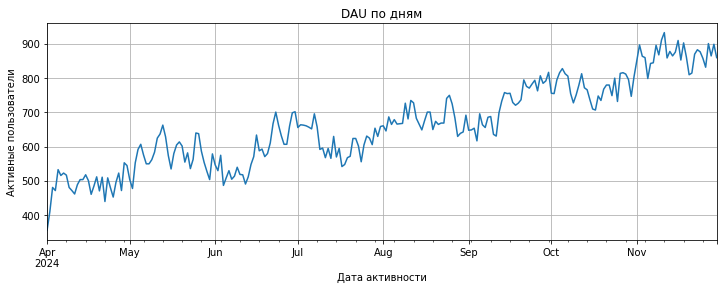

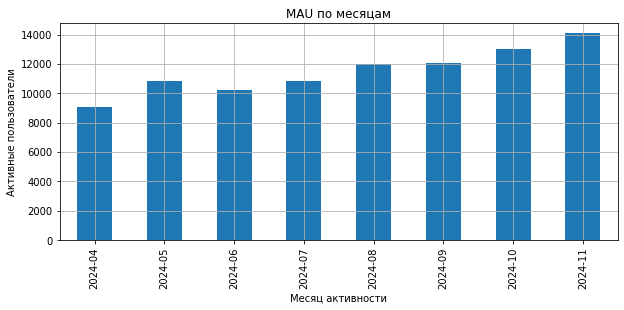

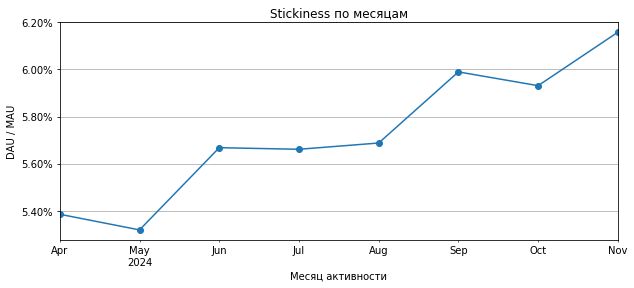

In [8]:
dau.plot(x='session_date', y='dau', figsize=(12, 4), grid=True, legend=False)
plt.title('DAU по дням')
plt.xlabel('Дата активности')
plt.ylabel('Активные пользователи')
plt.show()

mau['month'] = mau['activity_month'].dt.strftime('%Y-%m')
mau.plot(x='month', y='mau', kind='bar', figsize=(10, 4), grid=True, legend=False)
plt.title('MAU по месяцам')
plt.xlabel('Месяц активности')
plt.ylabel('Активные пользователи')
plt.show()

engagement_metrics.plot(
    x='activity_month',
    y='stickiness',
    marker='o',
    figsize=(10, 4),
    grid=True,
    legend=False,
)
plt.title('Stickiness по месяцам')
plt.xlabel('Месяц активности')
plt.ylabel('DAU / MAU')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()


,acquisition_month,users,costs,cac,revenue_28d,ltv,roi
0,2024-04-01,9069,6663.052333,0.734706,7425.63,0.818793,11.444870
1,2024-05-01,9789,7327.775412,0.748572,8141.76,0.831725,11.108209
2,2024-06-01,8719,8492.116887,0.973978,7447.84,0.854208,-12.297015
3,2024-07-01,8742,9217.078561,1.054344,9991.41,1.142920,8.401051
4,2024-08-01,9518,10999.013650,1.155601,10367.05,1.089205,-5.745639
5,2024-09-01,9198,10838.014747,1.178301,10085.88,1.096530,-6.939783
6,2024-10-01,9520,12595.403113,1.323047,11449.71,1.202701,-9.096121
7,2024-11-01,10301,13598.849128,1.320148,8893.98,0.863409,-34.597554


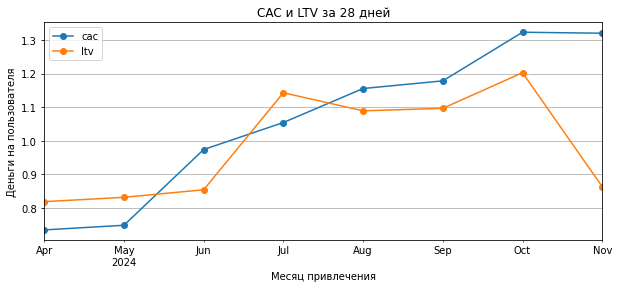

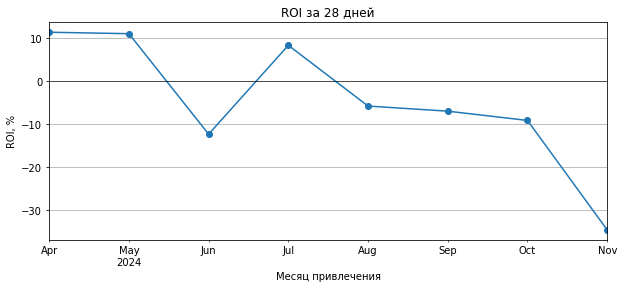

In [9]:
cohort_users = profiles.groupby('acquisition_month', as_index=False)['user_id'].nunique()
cohort_users = cohort_users.rename(columns={'user_id': 'users'})

monthly_costs = costs.groupby('cost_month', as_index=False)['costs'].sum()
monthly_costs = monthly_costs.rename(columns={'cost_month': 'acquisition_month'})

cohort_metrics = cohort_users.merge(monthly_costs, on='acquisition_month', how='left')
cohort_metrics['costs'] = cohort_metrics['costs'].fillna(0)
cohort_metrics['cac'] = cohort_metrics['costs'] / cohort_metrics['users']

orders_28d = orders[(orders['lifetime_days'] >= 0) & (orders['lifetime_days'] < 28)]
revenue_28d = orders_28d.groupby('acquisition_month', as_index=False)['revenue'].sum()
revenue_28d = revenue_28d.rename(columns={'revenue': 'revenue_28d'})

cohort_metrics = cohort_metrics.merge(revenue_28d, on='acquisition_month', how='left')
cohort_metrics['revenue_28d'] = cohort_metrics['revenue_28d'].fillna(0)
cohort_metrics['ltv'] = cohort_metrics['revenue_28d'] / cohort_metrics['users']
# ROI считаем в процентах.
cohort_metrics['roi'] = (cohort_metrics['ltv'] - cohort_metrics['cac']) / cohort_metrics['cac'] * 100

display(cohort_metrics)

cohort_metrics.plot(
    x='acquisition_month',
    y=['cac', 'ltv'],
    marker='o',
    figsize=(10, 4),
    grid=True,
)
plt.title('CAC и LTV за 28 дней')
plt.xlabel('Месяц привлечения')
plt.ylabel('Деньги на пользователя')
plt.show()

cohort_metrics.plot(x='acquisition_month', y='roi', marker='o', figsize=(10, 4), grid=True, legend=False)
plt.title('ROI за 28 дней')
plt.xlabel('Месяц привлечения')
plt.ylabel('ROI, %')
plt.axhline(0, color='black', linewidth=1, alpha=0.6)
plt.show()


### Промежуточный вывод

После появления спортивного контента активность пользователей в целом выросла: MAU увеличился с 9,1 тыс. в апреле до 14,1 тыс. в ноябре, средний DAU - с 488 до 868 пользователей. Stickiness тоже плавно улучшился: примерно с 5,4% до 6,2%, то есть пользователи стали немного регулярнее возвращаться в приложение.

При этом экономика привлечения ухудшилась. CAC после июня заметно вырос: с 0,73-0,75 в апреле-мае до 1,32 в октябре-ноябре. LTV за первые 28 дней тоже вырос после запуска нового контента, но не так быстро, как стоимость привлечения. В результате положительный ROI есть у апрельской, майской и июльской когорт, а июньская и когорты с августа по ноябрь не окупаются за ожидаемые 28 дней. Значит, стагнация выручки связана не с падением активности, а с тем, что маркетинговые расходы растут быстрее 28-дневной выручки на пользователя.


## Анализ метрик в разрезе источника привлечения

Теперь необходимо разобраться, какие источники привлечения перспективны, а какие за 28 дней не окупились.

**Задача 1**. Определите самые популярные источники привлечения:
- Посчитайте общее число привлечённых пользователей для каждого источника.
- Визуализируйте динамику набора новых пользователей по дням в каждом источнике.
- Рассчитайте и визуализируйте динамику DAU, MAU и Stickiness по источникам привлечения.

**Задача 2**. Изучите динамику изменения метрик на 28-й день в разрезе источника. Проведите анализ с выделением недельных когорт по дате привлечения. Рассчитайте и визуализируйте:
- Скользящее удержание на 14-й день с момента привлечения (за период с 14-го по 28-й день).
- Конверсию в покупку.

Недельную динамику затрат на маркетинг по каждому источнику привлечения.
Динамику среднего CAC, значений LTV и ROI.

По результатам проведите анализ рекламных каналов. Дайте общую характеристику каждому рекламному каналу по рассчитанным метрикам. Укажите, какие рекламные каналы не вышли на уровень окупаемости за ожидаемый период, и предположите почему.


,first_channel,users
0,FaceBoom,28401
3,TipTop,18118
2,RocketSuperAds,14257
1,MediaTornado,14080


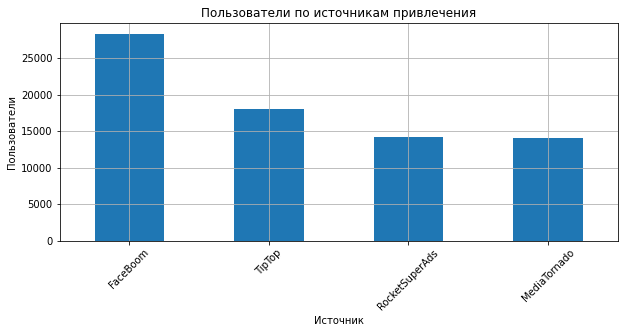

,first_date,first_channel,new_users
0,2024-04-01,FaceBoom,133
1,2024-04-01,MediaTornado,80
2,2024-04-01,RocketSuperAds,70
3,2024-04-01,TipTop,73
4,2024-04-02,FaceBoom,94


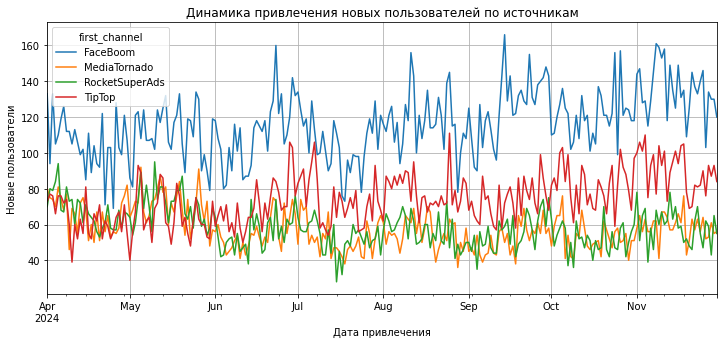

In [10]:
# Сколько пользователей пришло из каждого источника
channel_users = profiles.groupby('first_channel', as_index=False)['user_id'].nunique()
channel_users = channel_users.rename(columns={'user_id': 'users'})
channel_users = channel_users.sort_values('users', ascending=False)

display(channel_users)

channel_users.plot(x='first_channel', y='users', kind='bar', figsize=(10, 4), grid=True, legend=False)
plt.title('Пользователи по источникам привлечения')
plt.xlabel('Источник')
plt.ylabel('Пользователи')
plt.xticks(rotation=45)
plt.show()

# Динамика привлечения новых пользователей по дням
profiles['first_date'] = profiles['first_dt'].dt.normalize()

daily_new_users = profiles.groupby(['first_date', 'first_channel'], as_index=False)['user_id'].nunique()
daily_new_users = daily_new_users.rename(columns={'user_id': 'new_users'})

display(daily_new_users.head())

daily_new_users_plot = daily_new_users.pivot(
    index='first_date',
    columns='first_channel',
    values='new_users',
).fillna(0)

daily_new_users_plot.plot(figsize=(12, 5), grid=True)
plt.title('Динамика привлечения новых пользователей по источникам')
plt.xlabel('Дата привлечения')
plt.ylabel('Новые пользователи')
plt.show()


,activity_month,first_channel,mau,avg_dau,stickiness
0,2024-04-01,FaceBoom,3170,126.433333,0.039884
1,2024-04-01,MediaTornado,1969,121.100000,0.061503
2,2024-04-01,RocketSuperAds,2030,124.600000,0.061379
3,2024-04-01,TipTop,1900,116.200000,0.061158
4,2024-05-01,FaceBoom,3521,135.774194,0.038561
5,2024-05-01,MediaTornado,2546,147.645161,0.057991
6,2024-05-01,RocketSuperAds,2482,153.548387,0.061865
7,2024-05-01,TipTop,2300,140.000000,0.060870
8,2024-06-01,FaceBoom,3445,136.933333,0.039748
9,2024-06-01,MediaTornado,2119,118.966667,0.056143


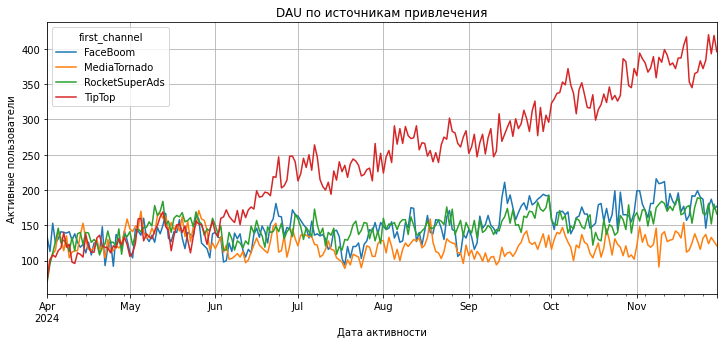

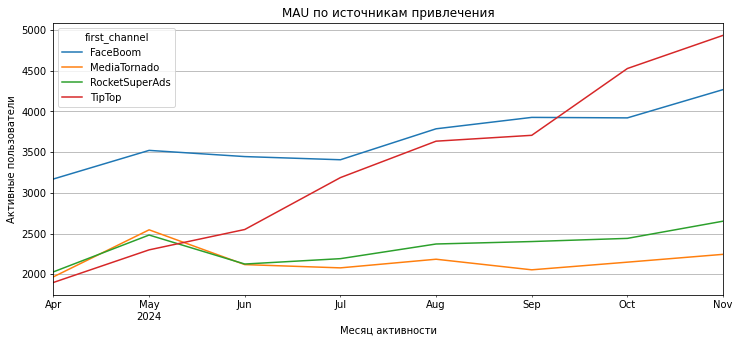

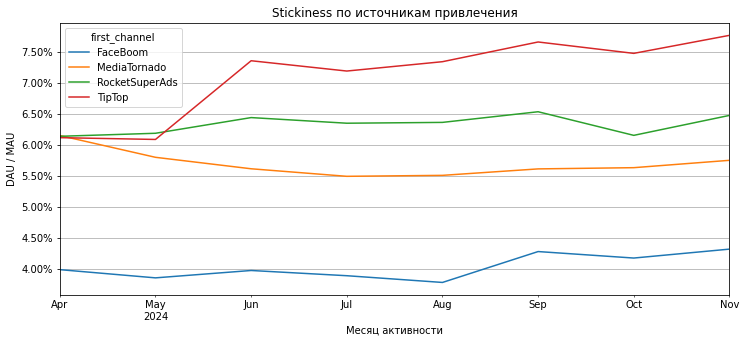

In [11]:
# DAU по источникам
source_dau = visits.groupby(['session_date', 'first_channel'], as_index=False)['user_id'].nunique()
source_dau = source_dau.rename(columns={'user_id': 'dau'})
source_dau['activity_month'] = source_dau['session_date'].dt.to_period('M').dt.to_timestamp()

# MAU по источникам
source_mau = visits.groupby(['activity_month', 'first_channel'], as_index=False)['user_id'].nunique()
source_mau = source_mau.rename(columns={'user_id': 'mau'})

# Средний DAU за месяц и Stickiness
source_avg_dau = source_dau.groupby(['activity_month', 'first_channel'], as_index=False)['dau'].mean()
source_avg_dau = source_avg_dau.rename(columns={'dau': 'avg_dau'})

source_engagement = source_mau.merge(source_avg_dau, on=['activity_month', 'first_channel'], how='left')
source_engagement['stickiness'] = source_engagement['avg_dau'] / source_engagement['mau']

display(source_engagement)

source_dau_plot = source_dau.pivot(index='session_date', columns='first_channel', values='dau').fillna(0)
source_dau_plot.plot(figsize=(12, 5), grid=True)
plt.title('DAU по источникам привлечения')
plt.xlabel('Дата активности')
plt.ylabel('Активные пользователи')
plt.show()

source_mau_plot = source_mau.pivot(index='activity_month', columns='first_channel', values='mau').fillna(0)
source_mau_plot.plot(figsize=(12, 5), grid=True)
plt.title('MAU по источникам привлечения')
plt.xlabel('Месяц активности')
plt.ylabel('Активные пользователи')
plt.show()

source_stickiness_plot = source_engagement.pivot(
    index='activity_month',
    columns='first_channel',
    values='stickiness',
).fillna(0)

source_stickiness_plot.plot(figsize=(12, 5), grid=True)
plt.title('Stickiness по источникам привлечения')
plt.xlabel('Месяц активности')
plt.ylabel('DAU / MAU')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()


,cohort_week,first_channel,users,retained_users,buyers,revenue_28d,costs,retention_14_28,conversion,cac,ltv,roi
0,2024-04-01,FaceBoom,820,10.0,93,380.36,769.875901,0.012195,0.113415,0.938873,0.463854,-50.594635
1,2024-04-01,MediaTornado,522,48.0,24,191.43,129.318322,0.091954,0.045977,0.247736,0.366724,48.030068
2,2024-04-01,RocketSuperAds,542,67.0,45,724.33,466.650000,0.123616,0.083026,0.860978,1.336402,55.219115
3,2024-04-01,TipTop,516,66.0,48,795.40,393.989381,0.127907,0.093023,0.763545,1.541473,101.883614
4,2024-04-08,FaceBoom,749,10.0,78,337.06,698.872741,0.013351,0.104139,0.933074,0.450013,-51.770905
...,...,...,...,...,...,...,...,...,...,...,...,...
135,2024-11-18,TipTop,567,0.0,84,880.49,1627.048850,0.000000,0.148148,2.869575,1.552892,-45.884231
136,2024-11-25,FaceBoom,763,0.0,66,278.22,872.983777,0.000000,0.086501,1.144146,0.364640,-68.129992
137,2024-11-25,MediaTornado,341,0.0,11,46.36,88.593183,0.000000,0.032258,0.259804,0.135953,-47.670917
138,2024-11-25,RocketSuperAds,331,0.0,25,136.07,138.125000,0.000000,0.075529,0.417296,0.411088,-1.487783


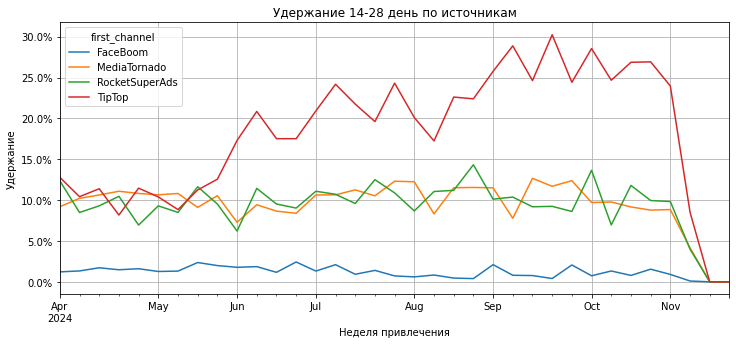

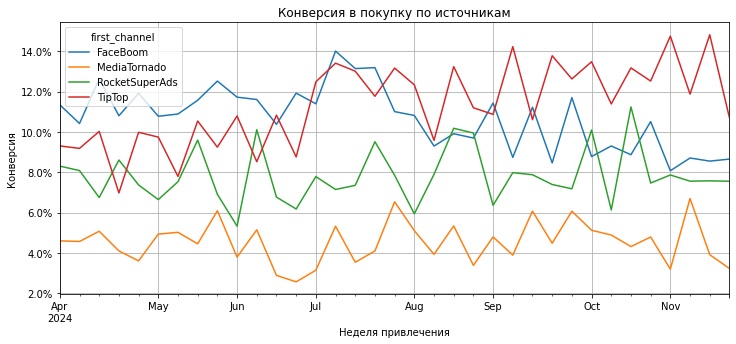

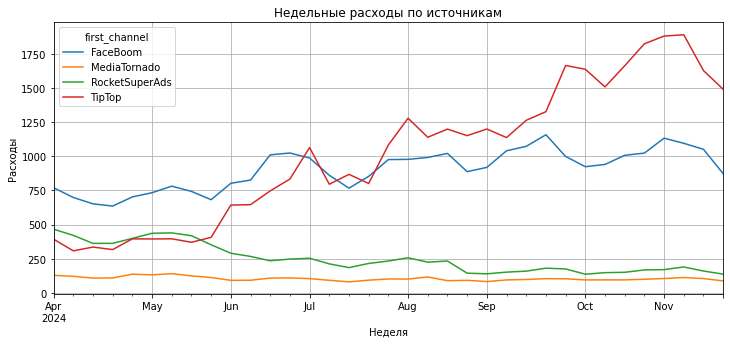

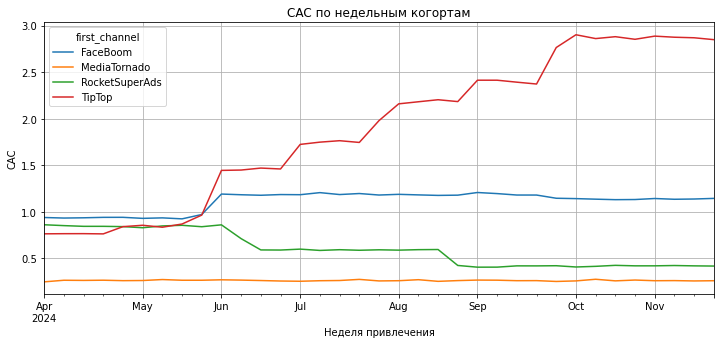

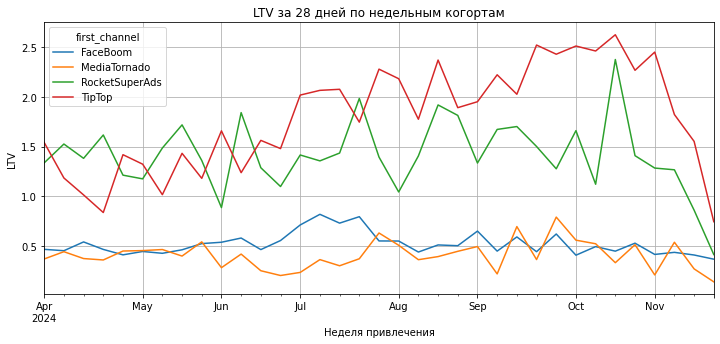

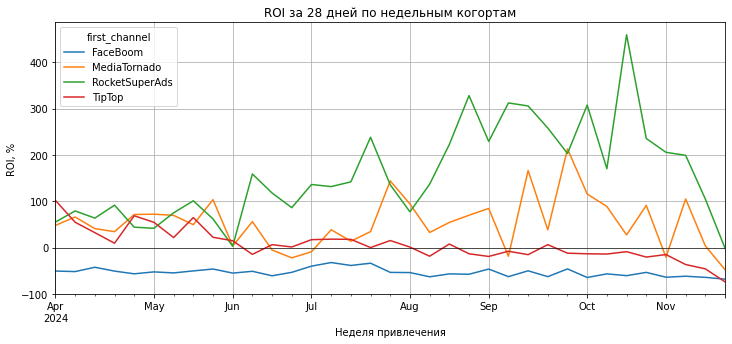

In [12]:
# Недельные когорты привлечения. Неделя начинается в понедельник.
profiles['cohort_week'] = profiles['first_dt'].dt.to_period('W-SUN').dt.start_time
visits['cohort_week'] = visits['first_dt'].dt.to_period('W-SUN').dt.start_time
orders['cohort_week'] = orders['first_dt'].dt.to_period('W-SUN').dt.start_time
costs['cohort_week'] = costs['dt'].dt.to_period('W-SUN').dt.start_time

cohort_users = profiles.groupby(['cohort_week', 'first_channel'], as_index=False)['user_id'].nunique()
cohort_users = cohort_users.rename(columns={'user_id': 'users'})

# Пользователь удержан, если был визит с 14-го по 28-й день включительно.
retention_visits = visits[(visits['lifetime_days'] >= 14) & (visits['lifetime_days'] < 28)]
retained_users = retention_visits.groupby(['cohort_week', 'first_channel'], as_index=False)['user_id'].nunique()
retained_users = retained_users.rename(columns={'user_id': 'retained_users'})

# Покупки за первые 28 дней после привлечения.
orders_28d = orders[(orders['lifetime_days'] >= 0) & (orders['lifetime_days'] < 28)]

buyers = orders_28d.groupby(['cohort_week', 'first_channel'], as_index=False)['user_id'].nunique()
buyers = buyers.rename(columns={'user_id': 'buyers'})

revenue_28d = orders_28d.groupby(['cohort_week', 'first_channel'], as_index=False)['revenue'].sum()
revenue_28d = revenue_28d.rename(columns={'revenue': 'revenue_28d'})

weekly_costs = costs.groupby(['cohort_week', 'channel'], as_index=False)['costs'].sum()
weekly_costs = weekly_costs.rename(columns={'channel': 'first_channel'})

source_weekly_metrics = cohort_users.merge(retained_users, on=['cohort_week', 'first_channel'], how='left')
source_weekly_metrics = source_weekly_metrics.merge(buyers, on=['cohort_week', 'first_channel'], how='left')
source_weekly_metrics = source_weekly_metrics.merge(revenue_28d, on=['cohort_week', 'first_channel'], how='left')
source_weekly_metrics = source_weekly_metrics.merge(weekly_costs, on=['cohort_week', 'first_channel'], how='left')
source_weekly_metrics = source_weekly_metrics.fillna(0)

source_weekly_metrics['retention_14_28'] = source_weekly_metrics['retained_users'] / source_weekly_metrics['users']
source_weekly_metrics['conversion'] = source_weekly_metrics['buyers'] / source_weekly_metrics['users']
source_weekly_metrics['cac'] = source_weekly_metrics['costs'] / source_weekly_metrics['users']
source_weekly_metrics['ltv'] = source_weekly_metrics['revenue_28d'] / source_weekly_metrics['users']
# ROI считаем в процентах.
source_weekly_metrics['roi'] = (source_weekly_metrics['ltv'] - source_weekly_metrics['cac']) / source_weekly_metrics['cac'] * 100

display(source_weekly_metrics)

retention_plot = source_weekly_metrics.pivot(index='cohort_week', columns='first_channel', values='retention_14_28').fillna(0)
retention_plot.plot(figsize=(12, 5), grid=True)
plt.title('Удержание 14-28 день по источникам')
plt.xlabel('Неделя привлечения')
plt.ylabel('Удержание')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

conversion_plot = source_weekly_metrics.pivot(index='cohort_week', columns='first_channel', values='conversion').fillna(0)
conversion_plot.plot(figsize=(12, 5), grid=True)
plt.title('Конверсия в покупку по источникам')
plt.xlabel('Неделя привлечения')
plt.ylabel('Конверсия')
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

costs_plot = source_weekly_metrics.pivot(index='cohort_week', columns='first_channel', values='costs').fillna(0)
costs_plot.plot(figsize=(12, 5), grid=True)
plt.title('Недельные расходы по источникам')
plt.xlabel('Неделя')
plt.ylabel('Расходы')
plt.show()

cac_plot = source_weekly_metrics.pivot(index='cohort_week', columns='first_channel', values='cac').fillna(0)
cac_plot.plot(figsize=(12, 5), grid=True)
plt.title('CAC по недельным когортам')
plt.xlabel('Неделя привлечения')
plt.ylabel('CAC')
plt.show()

ltv_plot = source_weekly_metrics.pivot(index='cohort_week', columns='first_channel', values='ltv').fillna(0)
ltv_plot.plot(figsize=(12, 5), grid=True)
plt.title('LTV за 28 дней по недельным когортам')
plt.xlabel('Неделя привлечения')
plt.ylabel('LTV')
plt.show()

roi_plot = source_weekly_metrics.pivot(index='cohort_week', columns='first_channel', values='roi').fillna(0)
roi_plot.plot(figsize=(12, 5), grid=True)
plt.title('ROI за 28 дней по недельным когортам')
plt.xlabel('Неделя привлечения')
plt.ylabel('ROI, %')
plt.axhline(0, color='black', linewidth=1, alpha=0.6)
plt.show()


### Промежуточный вывод по источникам

Самый проблемный источник - FaceBoom. Он приводит больше всего пользователей и забирает почти 40% рекламного бюджета, но ROI за первые 28 дней составляет около -54%. При этом удержание на 14-28-й день очень низкое, поэтому канал не возвращает вложения даже при заметном объеме привлечения.

TipTop тоже не окупается за 28 дней: ROI около -7%. У канала высокая конверсия и хорошее удержание, но CAC самый высокий среди всех источников, поэтому стандартного 28-дневного горизонта ему не хватает.

RocketSuperAds и MediaTornado выглядят эффективнее. RocketSuperAds дает самый высокий ROI за 28 дней, около 131%, за счет хорошего LTV при умеренном CAC. MediaTornado привлекает пользователей дешевле всего и тоже выходит в плюс, хотя конверсия ниже, чем у крупных каналов.


## Анализ периода окупаемости маркетинговых вложений

Для источников, которые к 28-му дню не выходят на уровень окупаемости, рассчитайте и визуализируйте в виде тепловой карты значения ROI за больший период, например за 8–10 недель.

Разделите данные на недельные когорты по дате привлечения, в качестве интервала наблюдений используйте недели.

Сделайте вывод о том, за какой период окупаются вложения в эти источники.

In [13]:
import seaborn as sns

# Берем готовые недельные метрики из предыдущей ячейки и агрегируем их по источникам.
source_roi_28d = source_weekly_metrics.groupby('first_channel', as_index=False).agg(
    users=('users', 'sum'),
    costs=('costs', 'sum'),
    revenue_28d=('revenue_28d', 'sum'),
)

source_roi_28d['cac'] = source_roi_28d['costs'] / source_roi_28d['users']
source_roi_28d['ltv_28d'] = source_roi_28d['revenue_28d'] / source_roi_28d['users']
# ROI считаем в процентах.
source_roi_28d['roi_28d'] = (source_roi_28d['ltv_28d'] - source_roi_28d['cac']) / source_roi_28d['cac'] * 100
source_roi_28d = source_roi_28d.sort_values('roi_28d')

problem_sources = source_roi_28d[source_roi_28d['roi_28d'] < 0]['first_channel'].tolist()

print('Источники для расширенного анализа:', problem_sources)
display(source_roi_28d)


Источники для расширенного анализа: ['FaceBoom', 'TipTop']


,first_channel,users,costs,revenue_28d,cac,ltv_28d,roi_28d
0,FaceBoom,28401,31621.374837,14564.96,1.113389,0.512833,-53.939511
3,TipTop,18118,35676.612846,33348.02,1.969125,1.840602,-6.526945
1,MediaTornado,14080,3688.941149,5727.33,0.261999,0.406771,55.256746
2,RocketSuperAds,14257,8744.375000,20162.95,0.613339,1.414249,130.581946


In [14]:
analysis_horizon = 10

# Переводим срок жизни пользователя в недели.
orders['lifetime_week'] = (orders['lifetime_days'] // 7).astype('Int64')

orders_10w = orders[
    (orders['first_channel'].isin(problem_sources))
    & (orders['lifetime_week'] >= 0)
    & (orders['lifetime_week'] < analysis_horizon)
]

weekly_revenue = orders_10w.groupby(
    ['cohort_week', 'first_channel', 'lifetime_week'],
    as_index=False,
)['revenue'].sum()

roi_base = source_weekly_metrics[source_weekly_metrics['first_channel'].isin(problem_sources)]
roi_base = roi_base[['cohort_week', 'first_channel', 'users', 'costs']].copy()

weeks = pd.DataFrame({'lifetime_week': range(analysis_horizon)})
roi_base['key'] = 1
weeks['key'] = 1

source_lifetime_roi = roi_base.merge(weeks, on='key').drop(columns='key')
source_lifetime_roi = source_lifetime_roi.merge(
    weekly_revenue,
    on=['cohort_week', 'first_channel', 'lifetime_week'],
    how='left',
)
source_lifetime_roi['revenue'] = source_lifetime_roi['revenue'].fillna(0)

source_lifetime_roi = source_lifetime_roi.sort_values(
    ['first_channel', 'cohort_week', 'lifetime_week']
)
source_lifetime_roi['cum_revenue'] = source_lifetime_roi.groupby(
    ['cohort_week', 'first_channel']
)['revenue'].cumsum()
# Накопительный ROI считаем в процентах.
source_lifetime_roi['roi'] = (source_lifetime_roi['cum_revenue'] - source_lifetime_roi['costs']) / source_lifetime_roi['costs'] * 100
source_lifetime_roi['week_number'] = source_lifetime_roi['lifetime_week'] + 1

# Для последних когорт не все 10 недель уже доступны в данных.
last_date = max(visits['session_start'].dt.normalize().max(), orders['event_dt'].dt.normalize().max())
source_lifetime_roi['week_end_date'] = source_lifetime_roi['cohort_week'] + pd.to_timedelta(
    source_lifetime_roi['week_number'] * 7 - 1,
    unit='D',
)
source_lifetime_roi.loc[source_lifetime_roi['week_end_date'] > last_date, 'roi'] = float('nan')

source_roi_by_lifetime = source_lifetime_roi[source_lifetime_roi['roi'].notna()]
source_roi_by_lifetime = source_roi_by_lifetime.groupby(
    ['first_channel', 'week_number'],
    as_index=False,
).agg(
    costs=('costs', 'sum'),
    cum_revenue=('cum_revenue', 'sum'),
)
source_roi_by_lifetime['roi'] = (source_roi_by_lifetime['cum_revenue'] - source_roi_by_lifetime['costs']) / source_roi_by_lifetime['costs'] * 100

payback_rows = source_lifetime_roi[source_lifetime_roi['roi'] >= 0]
payback_by_cohort = payback_rows.groupby(
    ['first_channel', 'cohort_week'],
    as_index=False,
)['week_number'].min()
payback_by_cohort = payback_by_cohort.rename(columns={'week_number': 'payback_week'})

complete_10w = source_lifetime_roi[
    (source_lifetime_roi['week_number'] == analysis_horizon)
    & (source_lifetime_roi['roi'].notna())
]
payback_summary = complete_10w.groupby('first_channel', as_index=False).agg(
    cohorts_with_10_weeks=('cohort_week', 'nunique'),
    avg_roi_10w=('roi', 'mean'),
    min_roi_10w=('roi', 'min'),
    max_roi_10w=('roi', 'max'),
)

paid_summary = payback_by_cohort.groupby('first_channel', as_index=False).agg(
    paid_cohorts=('cohort_week', 'nunique'),
    median_payback_week=('payback_week', 'median'),
    latest_payback_week=('payback_week', 'max'),
)

payback_summary = payback_summary.merge(paid_summary, on='first_channel', how='left')
payback_summary['paid_cohorts'] = payback_summary['paid_cohorts'].fillna(0).astype(int)

print('Накопительный ROI по неделям жизни пользователей:')
display(source_roi_by_lifetime)

print('Сводка по окупаемости недельных когорт:')
display(payback_summary)


Накопительный ROI по неделям жизни пользователей:


,first_channel,week_number,costs,cum_revenue,roi
0,FaceBoom,1,30748.391060,12812.53,-58.331056
1,FaceBoom,2,29697.311766,13318.10,-55.153853
2,FaceBoom,3,28602.242409,13274.20,-53.590352
3,FaceBoom,4,27469.634733,13083.74,-52.370171
4,FaceBoom,5,26446.305193,12749.28,-51.791829
5,FaceBoom,6,25439.032499,12453.97,-51.043854
6,FaceBoom,7,24498.577516,12162.73,-50.353322
7,FaceBoom,8,23574.846754,11898.01,-49.530913
8,FaceBoom,9,22575.812582,11395.96,-49.521374
9,FaceBoom,10,21418.149851,10994.09,-48.669282


Сводка по окупаемости недельных когорт:


,first_channel,cohorts_with_10_weeks,avg_roi_10w,min_roi_10w,max_roi_10w,paid_cohorts,median_payback_week,latest_payback_week
0,FaceBoom,25,-48.357840,-61.124904,-30.624227,0,NaN,NaN
1,TipTop,25,75.367364,21.719337,164.268544,30,4.0,7.0


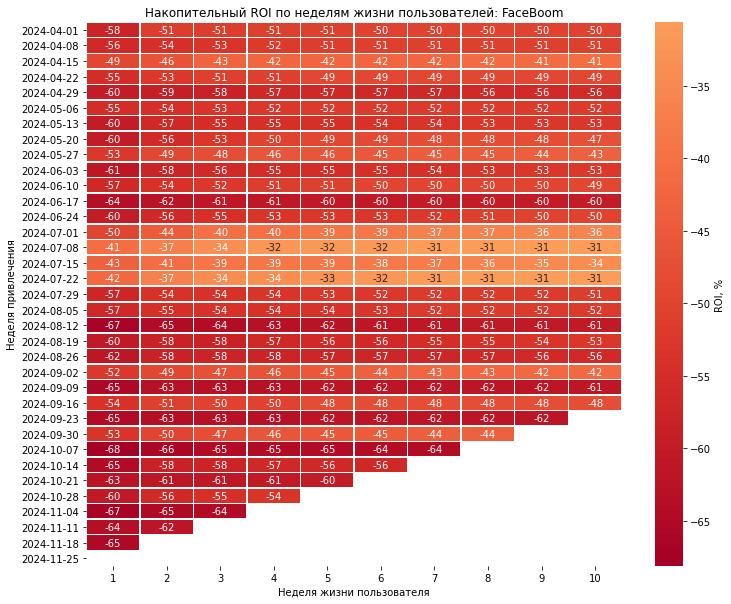

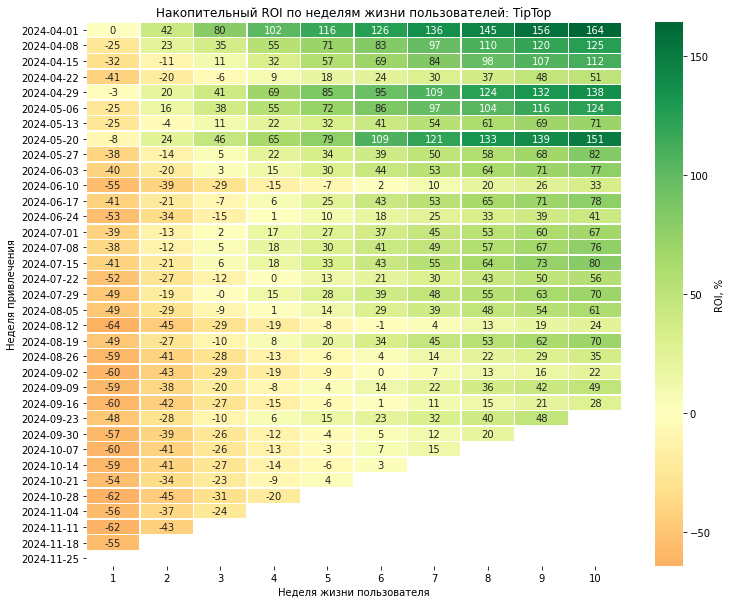

In [15]:
for source in problem_sources:
    source_data = source_lifetime_roi[source_lifetime_roi['first_channel'] == source]
    roi_heatmap = source_data.pivot(
        index='cohort_week',
        columns='week_number',
        values='roi',
    )
    roi_heatmap.index = roi_heatmap.index.strftime('%Y-%m-%d')

    plt.figure(figsize=(12, 10))
    ax = sns.heatmap(
        roi_heatmap,
        annot=True,
        fmt='.0f',
        cmap='RdYlGn',
        center=0,
        linewidths=0.5,
        linecolor='white',
    )
    ax.collections[0].colorbar.set_label('ROI, %')
    plt.title(f'Накопительный ROI по неделям жизни пользователей: {source}')
    plt.xlabel('Неделя жизни пользователя')
    plt.ylabel('Неделя привлечения')
    plt.show()

### Вывод по периоду окупаемости

К 28-му дню ниже уровня окупаемости находятся два источника: FaceBoom и TipTop. Для них был рассчитан накопительный ROI по недельным когортам привлечения на горизонте до 10 недель.

FaceBoom не окупается даже за 10 недель. Среди когорт, для которых доступен полный 10-недельный период наблюдения, средний ROI остается около -48%, а лучшая когорта также не выходит в плюс. Это означает, что проблема не только в коротком горизонте анализа: источник системно не возвращает маркетинговые вложения.

TipTop выглядит лучше. На горизонте 28 дней он немного ниже окупаемости, но при расширении периода большинство недельных когорт выходит в плюс примерно на 4-6-й неделе, а самый поздний срок окупаемости среди окупившихся когорт — 7-я неделя. Значит, для TipTop стандартный горизонт в 28 дней слишком короткий: вложения окупаются, но заметно позже первого месяца.


## Выводы и рекомендации

Активность продукта после запуска спортивного контента выросла: MAU увеличился с 9,1 тыс. в апреле до 14,1 тыс. в ноябре, средний DAU - с 488 до 868 пользователей, Stickiness - примерно с 5,4% до 6,2%. Значит, интерес к продукту не падает: пользователи чаще приходят и в целом становятся немного активнее.

Основная проблема находится в экономике привлечения. CAC после июня вырос быстрее, чем LTV за первые 28 дней. Из-за этого июньская когорта и когорты с августа по ноябрь не окупаются в ожидаемый срок, несмотря на рост активности и выручки на пользователя.

По источникам картина разная. RocketSuperAds - самый сильный канал: ROI за 28 дней около 131%, LTV заметно выше CAC. MediaTornado тоже окупается, в основном за счет очень низкой стоимости привлечения. TipTop почти окупается за 28 дней, но из-за высокого CAC выходит в плюс позже - обычно на 4-6-й неделе. FaceBoom остается главным слабым каналом: ROI за 28 дней около -54%, а за 10 недель вложения все равно не окупаются.

Рекомендации для маркетинга:

- Сократить или временно заморозить масштабирование FaceBoom, пока не будет понятна причина низкого удержания и слабой окупаемости.
- Для TipTop оценивать эффективность не только на 28-й день, но и на горизонте 6-7 недель; параллельно снижать CAC через ставки, аудитории и креативы.
- Поддерживать и аккуратно масштабировать RocketSuperAds, потому что канал приносит высокий LTV при умеренных расходах.
- Продолжать тестировать MediaTornado: канал дешевый и окупается, но стоит работать над конверсией в покупку.
- Ввести регулярный мониторинг ROI по недельным когортам, чтобы быстрее замечать рост CAC и неэффективные рекламные всплески.
